In [15]:
import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
import folium
# set display columns to max so that we can view all columns
pd.set_option('display.max_columns', None)

In [3]:
data = pd.read_csv("data/raw/US_Accidents_March23_NJ.csv")

In [4]:
data.head()

,ID,Source,Severity,Start_Time,End_Time,Start_Lat,Start_Lng,End_Lat,End_Lng,Distance(mi),Description,Street,City,County,State,Zipcode,Country,Timezone,Airport_Code,Weather_Timestamp,Temperature(F),Wind_Chill(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Direction,Wind_Speed(mph),Precipitation(in),Weather_Condition,Amenity,Bump,Crossing,Give_Way,Junction,No_Exit,Railway,Roundabout,Station,Stop,Traffic_Calming,Traffic_Signal,Turning_Loop,Sunrise_Sunset,Civil_Twilight,Nautical_Twilight,Astronomical_Twilight
0,A-194257,Source2,3,2016-11-30 16:25:41,2016-11-30 17:10:30,41.139324,-74.169876,NaN,NaN,0.01,Right lane blocked due to accident on I-87 Sou...,Route 17,Sloatsburg,Rockland,NY,10974,US,US/Eastern,KCDW,2016-11-30 16:53:00,53.1,NaN,93.0,29.81,1.0,East,11.5,0.00,Overcast,False,False,False,False,False,False,False,False,False,False,False,False,False,Day,Day,Day,Day
1,A-194258,Source2,3,2016-11-30 15:40:06,2016-11-30 17:09:40,41.118748,-74.159744,NaN,NaN,2.53,Accident on I-87 Southbound between Exit 14B C...,I-287 S,Suffern,Rockland,NY,10901,US,US/Eastern,KCDW,2016-11-30 15:53:00,53.1,NaN,93.0,29.83,1.0,ENE,8.1,0.02,Overcast,False,False,False,False,False,False,False,False,False,False,False,False,False,Day,Day,Day,Day
2,A-194259,Source2,3,2016-11-30 15:26:18,2016-11-30 16:56:02,41.014034,-73.717239,NaN,NaN,1.17,Accident on I-287 Cross Westchester Expy Eastb...,Hutchinson River Pkwy S,White Plains,Westchester,NY,10605,US,US/Eastern,KHPN,2016-11-30 15:56:00,52.0,NaN,93.0,29.81,2.0,East,17.3,0.15,Light Rain,False,False,False,False,True,False,False,False,False,False,False,False,False,Day,Day,Day,Day
3,A-194260,Source2,3,2016-11-30 16:14:11,2016-11-30 16:59:00,41.390369,-73.597969,NaN,NaN,0.01,Right hand shoulder blocked due to accident on...,I-84 E,Brewster,Putnam,NY,10509,US,US/Eastern,KDXR,2016-11-30 15:53:00,52.0,NaN,89.0,29.86,3.0,East,10.4,0.05,Rain,False,False,False,False,False,False,False,False,False,False,False,False,False,Day,Day,Day,Day
4,A-194261,Source2,3,2016-11-30 16:17:57,2016-11-30 17:02:44,41.390369,-73.597969,NaN,NaN,0.01,Right hand shoulder blocked due to accident on...,I-84 E,Brewster,Putnam,NY,10509,US,US/Eastern,KDXR,2016-11-30 15:53:00,52.0,NaN,89.0,29.86,3.0,East,10.4,0.05,Rain,False,False,False,False,False,False,False,False,False,False,False,False,False,Day,Day,Day,Day


In [5]:
data.shape

(347960, 46)

In [6]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 347960 entries, 0 to 347959
Data columns (total 46 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   ID                     347960 non-null  object 
 1   Source                 347960 non-null  object 
 2   Severity               347960 non-null  int64  
 3   Start_Time             347960 non-null  object 
 4   End_Time               347960 non-null  object 
 5   Start_Lat              347960 non-null  float64
 6   Start_Lng              347960 non-null  float64
 7   End_Lat                194902 non-null  float64
 8   End_Lng                194902 non-null  float64
 9   Distance(mi)           347960 non-null  float64
 10  Description            347959 non-null  object 
 11  Street                 347312 non-null  object 
 12  City                   347932 non-null  object 
 13  County                 347960 non-null  object 
 14  State                  347960 non-nu

## Exploratory Data Analysis (EDA)

This section performs initial exploratory analysis on the New Jersey accidents dataset. It includes:
- Data shape and brief preview
- Missing value summary
- Target (Severity) distribution
- Time-based features (hour, weekday)
- Numeric correlations
- Top cities/counties/streets
- A small sample map saved to `data/raw/accidents_map_sample.html`

In [7]:
# Ensure dataframe is loaded (the notebook earlier loads df; if not, load here)
try:
    data
except NameError:
    data = pd.read_csv("data/raw/US_Accidents_March23_NJ.csv", index_col='id')

print("Shape:", data.shape)
print('\nColumns:')
print(list(data.columns))

# show head
display(data.head())

# basic info
print('\nInfo:')
data.info()

# basic describe for numeric
print('\nNumeric summary (describe):')
display(data.describe(include=[np.number]).T)

Shape: (347960, 46)

Columns:
['ID', 'Source', 'Severity', 'Start_Time', 'End_Time', 'Start_Lat', 'Start_Lng', 'End_Lat', 'End_Lng', 'Distance(mi)', 'Description', 'Street', 'City', 'County', 'State', 'Zipcode', 'Country', 'Timezone', 'Airport_Code', 'Weather_Timestamp', 'Temperature(F)', 'Wind_Chill(F)', 'Humidity(%)', 'Pressure(in)', 'Visibility(mi)', 'Wind_Direction', 'Wind_Speed(mph)', 'Precipitation(in)', 'Weather_Condition', 'Amenity', 'Bump', 'Crossing', 'Give_Way', 'Junction', 'No_Exit', 'Railway', 'Roundabout', 'Station', 'Stop', 'Traffic_Calming', 'Traffic_Signal', 'Turning_Loop', 'Sunrise_Sunset', 'Civil_Twilight', 'Nautical_Twilight', 'Astronomical_Twilight']


,ID,Source,Severity,Start_Time,End_Time,Start_Lat,Start_Lng,End_Lat,End_Lng,Distance(mi),Description,Street,City,County,State,Zipcode,Country,Timezone,Airport_Code,Weather_Timestamp,Temperature(F),Wind_Chill(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Direction,Wind_Speed(mph),Precipitation(in),Weather_Condition,Amenity,Bump,Crossing,Give_Way,Junction,No_Exit,Railway,Roundabout,Station,Stop,Traffic_Calming,Traffic_Signal,Turning_Loop,Sunrise_Sunset,Civil_Twilight,Nautical_Twilight,Astronomical_Twilight
0,A-194257,Source2,3,2016-11-30 16:25:41,2016-11-30 17:10:30,41.139324,-74.169876,NaN,NaN,0.01,Right lane blocked due to accident on I-87 Sou...,Route 17,Sloatsburg,Rockland,NY,10974,US,US/Eastern,KCDW,2016-11-30 16:53:00,53.1,NaN,93.0,29.81,1.0,East,11.5,0.00,Overcast,False,False,False,False,False,False,False,False,False,False,False,False,False,Day,Day,Day,Day
1,A-194258,Source2,3,2016-11-30 15:40:06,2016-11-30 17:09:40,41.118748,-74.159744,NaN,NaN,2.53,Accident on I-87 Southbound between Exit 14B C...,I-287 S,Suffern,Rockland,NY,10901,US,US/Eastern,KCDW,2016-11-30 15:53:00,53.1,NaN,93.0,29.83,1.0,ENE,8.1,0.02,Overcast,False,False,False,False,False,False,False,False,False,False,False,False,False,Day,Day,Day,Day
2,A-194259,Source2,3,2016-11-30 15:26:18,2016-11-30 16:56:02,41.014034,-73.717239,NaN,NaN,1.17,Accident on I-287 Cross Westchester Expy Eastb...,Hutchinson River Pkwy S,White Plains,Westchester,NY,10605,US,US/Eastern,KHPN,2016-11-30 15:56:00,52.0,NaN,93.0,29.81,2.0,East,17.3,0.15,Light Rain,False,False,False,False,True,False,False,False,False,False,False,False,False,Day,Day,Day,Day
3,A-194260,Source2,3,2016-11-30 16:14:11,2016-11-30 16:59:00,41.390369,-73.597969,NaN,NaN,0.01,Right hand shoulder blocked due to accident on...,I-84 E,Brewster,Putnam,NY,10509,US,US/Eastern,KDXR,2016-11-30 15:53:00,52.0,NaN,89.0,29.86,3.0,East,10.4,0.05,Rain,False,False,False,False,False,False,False,False,False,False,False,False,False,Day,Day,Day,Day
4,A-194261,Source2,3,2016-11-30 16:17:57,2016-11-30 17:02:44,41.390369,-73.597969,NaN,NaN,0.01,Right hand shoulder blocked due to accident on...,I-84 E,Brewster,Putnam,NY,10509,US,US/Eastern,KDXR,2016-11-30 15:53:00,52.0,NaN,89.0,29.86,3.0,East,10.4,0.05,Rain,False,False,False,False,False,False,False,False,False,False,False,False,False,Day,Day,Day,Day



Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 347960 entries, 0 to 347959
Data columns (total 46 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   ID                     347960 non-null  object 
 1   Source                 347960 non-null  object 
 2   Severity               347960 non-null  int64  
 3   Start_Time             347960 non-null  object 
 4   End_Time               347960 non-null  object 
 5   Start_Lat              347960 non-null  float64
 6   Start_Lng              347960 non-null  float64
 7   End_Lat                194902 non-null  float64
 8   End_Lng                194902 non-null  float64
 9   Distance(mi)           347960 non-null  float64
 10  Description            347959 non-null  object 
 11  Street                 347312 non-null  object 
 12  City                   347932 non-null  object 
 13  County                 347960 non-null  object 
 14  State                  347960

,count,mean,std,min,25%,50%,75%,max
Severity,347960.0,2.259550,0.511014,1.000000,2.000000,2.000000,2.000000,4.000000
Start_Lat,347960.0,41.560975,0.999105,40.503048,40.758131,40.976681,42.743330,45.001892
Start_Lng,347960.0,-74.556611,1.574805,-79.761920,-74.088270,-73.894638,-73.760542,-71.861031
End_Lat,194902.0,41.536836,0.999496,40.505200,40.750500,40.918790,42.714843,44.997320
End_Lng,194902.0,-74.526908,1.528085,-79.761981,-74.076729,-73.903030,-73.769342,-71.943680
Distance(mi),347960.0,0.751562,2.124309,0.000000,0.000000,0.069000,0.713000,112.903000
Temperature(F),345892.0,54.840956,19.336263,-77.800000,39.000000,56.000000,71.000000,172.000000
Wind_Chill(F),276306.0,49.544803,23.010782,-39.000000,31.000000,52.000000,69.000000,172.000000
Humidity(%),345769.0,65.880507,20.201403,1.000000,50.000000,66.000000,84.000000,100.000000
Pressure(in),344976.0,29.813697,0.382717,19.750000,29.600000,29.870000,30.070000,30.890000


In [8]:
# Missing values summary
missing = data.isnull().sum().sort_values(ascending=False)
print('Columns with missing values (top 30):')
display(missing[missing > 0].head(30))

# Fraction missing
miss_frac = (data.isnull().mean() * 100).sort_values(ascending=False)
display(miss_frac[miss_frac > 0].head(30))

Columns with missing values (top 30):


End_Lat                  153058
End_Lng                  153058
Precipitation(in)         86511
Wind_Chill(F)             71654
Wind_Speed(mph)           17879
Wind_Direction             4477
Visibility(mi)             3081
Pressure(in)               2984
Weather_Condition          2726
Humidity(%)                2191
Temperature(F)             2068
Weather_Timestamp          1459
Nautical_Twilight           710
Civil_Twilight              710
Sunrise_Sunset              710
Astronomical_Twilight       710
Street                      648
Airport_Code                347
City                         28
Description                   1
dtype: int64

End_Lat                  43.987240
End_Lng                  43.987240
Precipitation(in)        24.862340
Wind_Chill(F)            20.592597
Wind_Speed(mph)           5.138234
Wind_Direction            1.286642
Visibility(mi)            0.885447
Pressure(in)              0.857570
Weather_Condition         0.783423
Humidity(%)               0.629670
Temperature(F)            0.594321
Weather_Timestamp         0.419301
Nautical_Twilight         0.204046
Civil_Twilight            0.204046
Sunrise_Sunset            0.204046
Astronomical_Twilight     0.204046
Street                    0.186228
Airport_Code              0.099724
City                      0.008047
Description               0.000287
dtype: float64

C:\Users\suvar\AppData\Local\Temp\ipykernel_23368\3040033264.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Severity', data=data, palette='viridis')


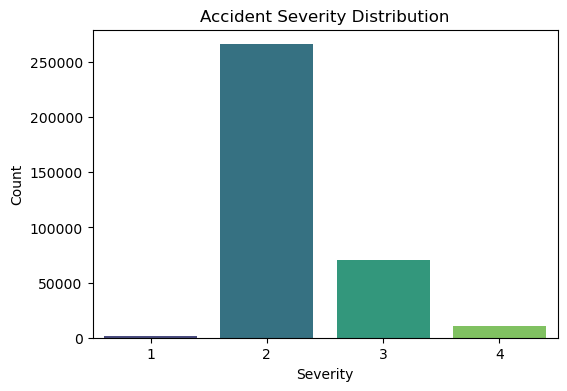


Severity counts:


2    265902
3     70062
4     10749
1      1247
Name: Severity, dtype: int64

In [9]:
# Severity distribution (if present)
if 'Severity' in data.columns:
    plt.figure(figsize=(6,4))
    sns.countplot(x='Severity', data=data, palette='viridis')
    plt.title('Accident Severity Distribution')
    plt.ylabel('Count')
    plt.show()
    print('\nSeverity counts:')
    display(data['Severity'].value_counts())
else:
    print('Column "Severity" not found in dataset.')

Sample Start_Time features:


,Start_Time,Start_Hour,Start_Weekday
0,2016-11-30 16:25:41,16,Wednesday
1,2016-11-30 15:40:06,15,Wednesday
2,2016-11-30 15:26:18,15,Wednesday
3,2016-11-30 16:14:11,16,Wednesday
4,2016-11-30 16:17:57,16,Wednesday


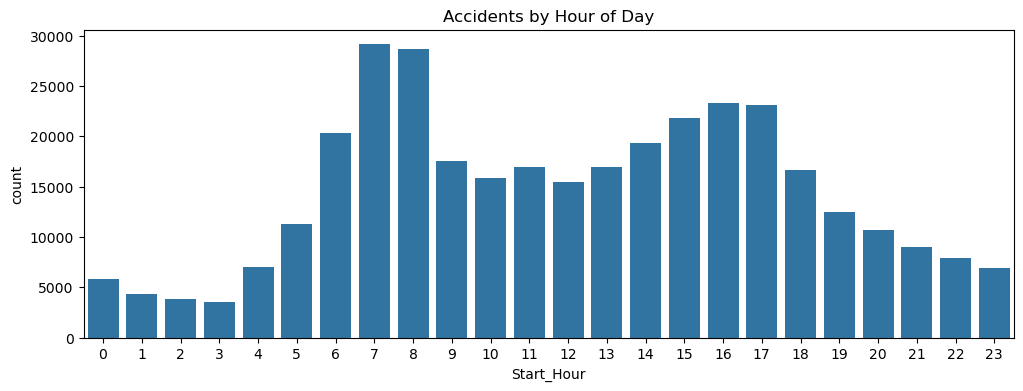

C:\Users\suvar\AppData\Local\Temp\ipykernel_23368\3021953330.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Start_Weekday', data=data, order=order, palette='coolwarm')


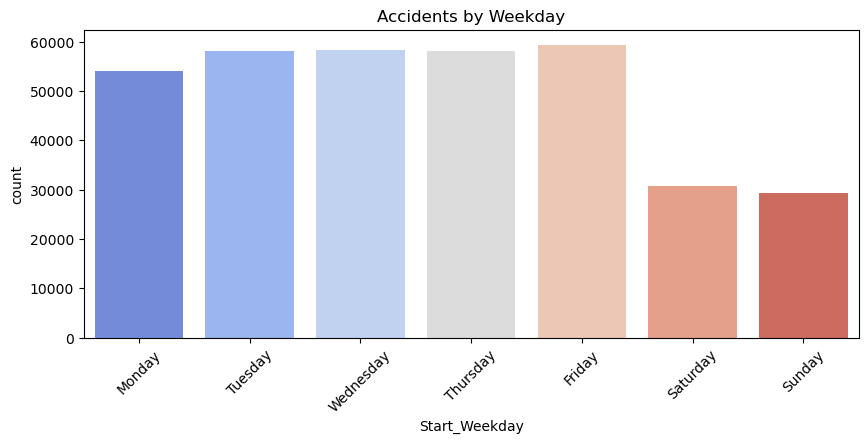

In [11]:
# Parse date/time and extract features
if 'Start_Time' in data.columns:
    data['Start_Time'] = pd.to_datetime(data['Start_Time'], errors='coerce')
    data['Start_Hour'] = data['Start_Time'].dt.hour
    data['Start_Weekday'] = data['Start_Time'].dt.day_name()
    print('Sample Start_Time features:')
    display(data[['Start_Time','Start_Hour','Start_Weekday']].head())

    # plot hour distribution
    plt.figure(figsize=(12,4))
    sns.countplot(x='Start_Hour', data=data, color='tab:blue')
    plt.title('Accidents by Hour of Day')
    plt.show()

    # weekday
    plt.figure(figsize=(10,4))
    order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
    sns.countplot(x='Start_Weekday', data=data, order=order, palette='coolwarm')
    plt.title('Accidents by Weekday')
    plt.xticks(rotation=45)
    plt.show()
else:
    print('Column "Start_Time" not found; skipping time-based features.')

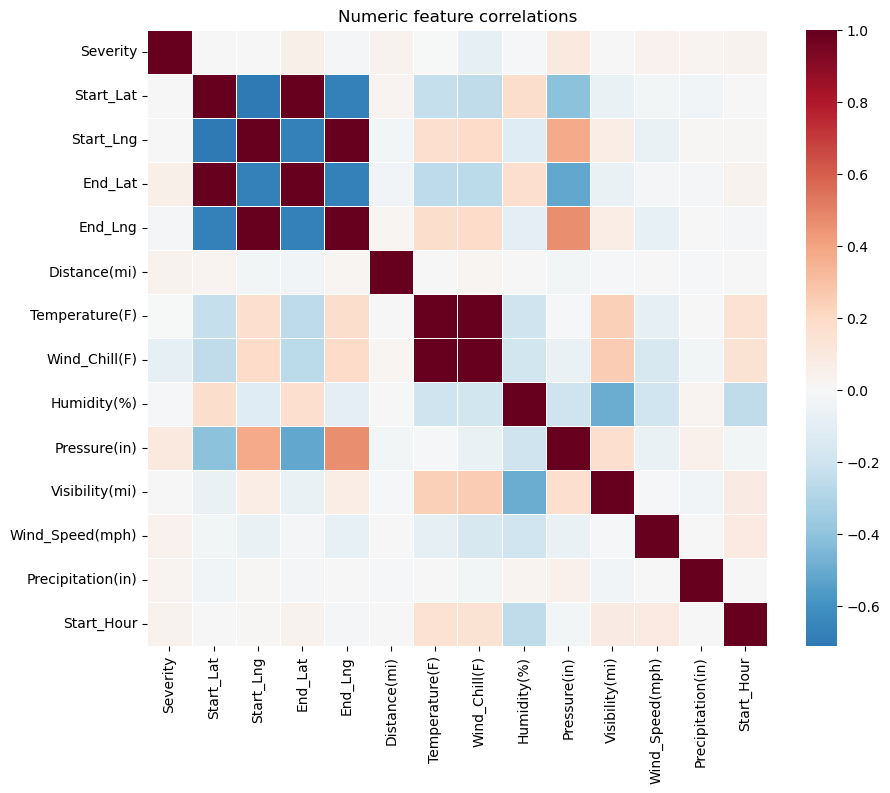


Top 10 Citys:


Bronx            27297
Rochester        24743
New York         21699
Brooklyn         21357
Buffalo           9574
Albany            7403
Staten Island     5806
Flushing          5662
Syracuse          5394
Jamaica           4774
Name: City, dtype: int64


Top 10 Countys:


Queens         41480
Westchester    38224
Monroe         32480
Bronx          27308
Nassau         23325
New York       21989
Suffolk        21828
Kings          21234
Albany         13855
Erie           12818
Name: County, dtype: int64


Top 10 Streets:


I-90 W                   9881
Brooklyn Queens Expy     9549
I-90 E                   8231
Long Island Expy W       7501
Long Island Expy E       7261
I-87 S                   4673
I-87 N                   4013
Southern State Pkwy E    3937
Major Deegan Expy N      3386
Southern State Pkwy W    3365
Name: Street, dtype: int64

In [13]:
# Numeric correlation heatmap (safe selection)
num_cols = data.select_dtypes(include=[np.number]).columns.tolist()
if len(num_cols) > 1:
    corr = data[num_cols].corr()
    plt.figure(figsize=(10,8))
    sns.heatmap(corr, cmap='RdBu_r', center=0, linewidths=.5)
    plt.title('Numeric feature correlations')
    plt.show()
else:
    print('Not enough numeric columns for correlation matrix.')

# Show top counts for City / County / Street if available
for col in ['City','County','Street']:
    if col in data.columns:
        print(f"\nTop 10 {col}s:")
        display(data[col].value_counts().head(10))
    else:
        print(f"Column {col} not found.")


In [16]:
# Create a small folium map sample (saved to HTML)
if 'Start_Lat' in data.columns and 'Start_Lng' in data.columns:
    try:
        sample = data.dropna(subset=['Start_Lat','Start_Lng']).iloc[:500]
        center_lat = sample['Start_Lat'].median()
        center_lng = sample['Start_Lng'].median()
        m = folium.Map(location=[center_lat, center_lng], zoom_start=10)
        for _, r in sample.iterrows():
            folium.CircleMarker([r['Start_Lat'], r['Start_Lng']], radius=2, color='red', fill=True, fill_opacity=0.6).add_to(m)
        out_html = 'data/raw/accidents_map_sample.html'
        m.save(out_html)
        print(f'Saved sample map to {out_html}')
    except Exception as e:
        print('Failed to create folium map:', e)
else:
    print('No Start_Lat/Start_Lng columns found; skipping map creation.')

Saved sample map to data/raw/accidents_map_sample.html
